# Evidential classification: train, validate, then test

This CPU tutorial trains the package's `CategoricalDNN` and original EDL digamma
loss on three overlapping synthetic classes. It requires no downloads and runs in
about a minute on a typical CPU. It demonstrates the workflow, not the paper's
precipitation-type benchmark.

Install in a Python 3.11 environment with `python -m pip install -e ".[torch,notebooks]"`,
select that environment's Jupyter kernel, then **Restart Kernel and Run All**.
The installed package is imported without working-directory assumptions.

The 60% training partition fits preprocessing and model weights; 20% validation
selects the best predictive log loss; the final 20% is an untouched test set.
All settings are fixed before that test set is evaluated.


Based on the original MILES-GUESS examples by John Schreck, David John Gagne, Charlie Becker, Gabrielle Gantos, Dhamma Kimpara, and Thomas Martin. This modernized tutorial uses new synthetic data and preserves the package's scientific loss.


In [1]:
import copy
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 2026
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
device = torch.device("cpu")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | "
      f"NumPy {np.__version__} | SciPy {scipy.__version__} | device: {device}")

from sklearn.datasets import make_blobs
from mlguess.torch.models import CategoricalDNN
from mlguess.torch.class_losses import edl_digamma_loss
from mlguess.evaluation import evaluate_classifier


Python 3.11.17 | PyTorch 2.14.1+cpu | NumPy 2.4.6 | SciPy 1.17.1 | device: cpu


## 1. Make three overlapping classes and split before scaling

The classes overlap deliberately: some uncertainty is irreducible from these two
features. Stratification retains class representation in each partition. Independent
rows justify a random split here; grouped subjects, stations, and time series need a
group or chronological split instead. All input scaling is fitted on training rows.


Rows: train=1440, validation=480, reserved test=480


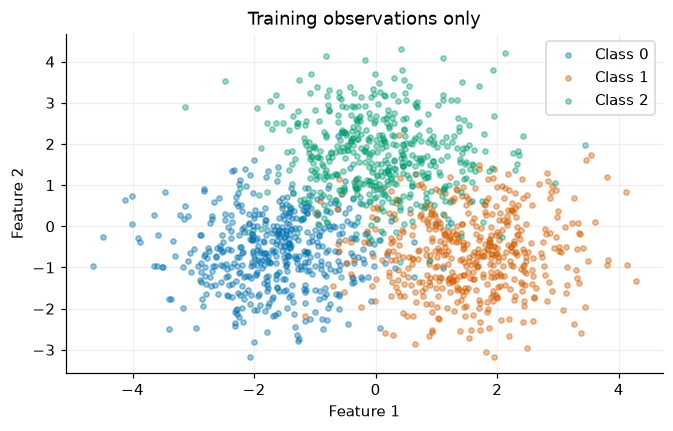

In [2]:
X, y = make_blobs(n_samples=2400, centers=[[-1.7, -0.7], [1.5, -0.7], [0.0, 1.6]],
                  cluster_std=[0.85, 0.95, 0.90], random_state=SEED)
num_classes = 3
class_names = np.array(["Class 0", "Class 1", "Class 2"])
colors = ["#0072B2", "#D55E00", "#009E73"]
development, test_idx = train_test_split(np.arange(len(X)), test_size=0.20,
                                        stratify=y, random_state=SEED)
train_idx, valid_idx = train_test_split(development, test_size=0.25,
                                       stratify=y[development], random_state=SEED + 1)
assert not (set(train_idx) & set(valid_idx) or set(train_idx) & set(test_idx)
            or set(valid_idx) & set(test_idx))
print(f"Rows: train={len(train_idx)}, validation={len(valid_idx)}, reserved test={len(test_idx)}")
x_scaler = StandardScaler().fit(X[train_idx])
as_tensor = lambda array: torch.as_tensor(array, dtype=torch.float32, device=device)
x_train = as_tensor(x_scaler.transform(X[train_idx]))
x_valid = as_tensor(x_scaler.transform(X[valid_idx]))
y_train = torch.as_tensor(y[train_idx], dtype=torch.long, device=device)
y_valid = torch.as_tensor(y[valid_idx], dtype=torch.long, device=device)
loader = DataLoader(TensorDataset(x_train, y_train), batch_size=128, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED), num_workers=0)

fig, ax = plt.subplots(figsize=(7, 4))
for k in range(num_classes):
    rows = train_idx[y[train_idx] == k]
    ax.scatter(X[rows, 0], X[rows, 1], s=12, alpha=0.4, color=colors[k], label=class_names[k])
ax.set(title="Training observations only", xlabel="Feature 1", ylabel="Feature 2")
ax.legend(); plt.show()


## 2. Train evidence and select by validation log loss

Raw network outputs become nonnegative evidence through ReLU. The Dirichlet
concentrations are $\alpha_k=\operatorname{ReLU}(z_k)+1$, and predictive class
probabilities are $p_k=\alpha_k/\sum_j\alpha_j$. Do not apply softmax to the
evidence head. The EDL loss receives one-hot targets and the explicit `device`
keyword; its KL regularizer is annealed over the first 25 epochs.

The validation score is predictive log loss without the annealed penalty. This
makes checkpoint scores comparable across epochs. We retain the package's loss
formula and do not tune on the test set.


Frozen validation-selected epoch 197; trained 200 epochs in 4.7 s. No test predictions made yet.


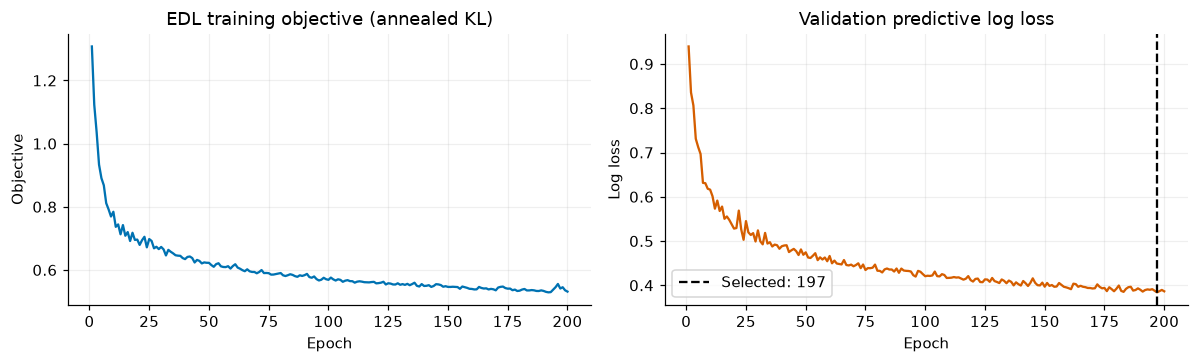

In [3]:
torch.manual_seed(SEED)
model = CategoricalDNN(input_size=2, output_size=num_classes, layer_size=[64, 64],
                       dr=[0.0, 0.0], batch_norm=False, softmax=False).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
max_epochs, patience, annealing_step = 200, 40, 25
history, best_score, best_epoch, best_state = [], float("inf"), 0, None
started = time.perf_counter()

for epoch in range(1, max_epochs + 1):
    model.train()
    loss_sum = 0.0
    for xb, yb in loader:
        optimizer.zero_grad(set_to_none=True)
        target = torch.nn.functional.one_hot(yb, num_classes=num_classes).float()
        loss = edl_digamma_loss(model(xb), target, epoch_num=epoch,
                                num_classes=num_classes, annealing_step=annealing_step,
                                device=device)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss")
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(xb)
    model.eval()
    with torch.no_grad():
        alpha = torch.relu(model(x_valid)) + 1.0
        p_valid = alpha / alpha.sum(dim=1, keepdim=True)
        valid_log_loss = -p_valid[torch.arange(len(y_valid)), y_valid].log().mean().item()
    history.append({"epoch": epoch, "train_objective": loss_sum / len(x_train),
                    "valid_log_loss": valid_log_loss})
    if valid_log_loss < best_score:
        best_score, best_epoch, best_state = valid_log_loss, epoch, copy.deepcopy(model.state_dict())
    if epoch - best_epoch >= patience:
        break

assert best_state is not None
model.load_state_dict(best_state)
model.eval()
model.requires_grad_(False)
history = pd.DataFrame(history)
print(f"Frozen validation-selected epoch {best_epoch}; trained {len(history)} epochs "
      f"in {time.perf_counter() - started:.1f} s. No test predictions made yet.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(history.epoch, history.train_objective, color="#0072B2")
axes[0].set(title="EDL training objective (annealed KL)", xlabel="Epoch", ylabel="Objective")
axes[1].plot(history.epoch, history.valid_log_loss, color="#D55E00")
axes[1].axvline(best_epoch, color="black", linestyle="--", label=f"Selected: {best_epoch}")
axes[1].set(title="Validation predictive log loss", xlabel="Epoch", ylabel="Log loss")
axes[1].legend(); fig.tight_layout(); plt.show()


## 3. Freeze, then evaluate the untouched test partition

Accuracy measures hard-label correctness. Log loss and the multiclass Brier score
measure probabilistic predictions; smaller is better. Here Brier is the **sum** of
squared probability errors over classes, averaged over observations. ECE is a
10-bin, count-weighted top-label calibration error. Its value depends on binning
and sample size, so inspect the reliability diagram and bin counts as well.

For each class indicator, with $S=\sum_k\alpha_k$,
$A_k=p_k(1-p_k)S/(S+1)$ and $E_k=p_k(1-p_k)/(S+1)$.
Their sum is $p_k(1-p_k)$ by the law of total variance. These are marginal
indicator variances; they are not a scalar variance of numeric class labels.
The separate quantity $u=K/S$ is an evidence-based uncertainty score, not a probability of error.


In [4]:
x_test = as_tensor(x_scaler.transform(X[test_idx]))
with torch.no_grad():
    probabilities, evidence_uncertainty, aleatoric, epistemic = (
        value.cpu().numpy() for value in model.predict(x_test)
    )
test = evaluate_classifier(y[test_idx], probabilities, n_bins=10)
predicted = probabilities.argmax(axis=1)
correct = predicted == y[test_idx]
assert np.allclose(probabilities.sum(axis=1), 1.0)
assert np.allclose(aleatoric + epistemic, probabilities * (1.0 - probabilities), atol=1e-7)
assert np.isfinite(list(test["metrics"].values())).all()
display(pd.DataFrame([test["metrics"]], index=["untouched test"]).round(4))
display(test["reliability"].round(4))
display(pd.DataFrame({"mean aleatoric variance": aleatoric.mean(axis=0),
                      "mean epistemic variance": epistemic.mean(axis=0)}, index=class_names).round(4))


,accuracy,log_loss,brier,ece
untouched test,0.8875,0.4308,0.2063,0.1378


,lower,upper,count,confidence,accuracy
0,0.0,0.1,0,NaN,NaN
1,0.1,0.2,0,NaN,NaN
2,0.2,0.3,0,NaN,NaN
3,0.3,0.4,9,0.3467,0.4444
4,0.4,0.5,26,0.4471,0.5769
5,0.5,0.6,23,0.5498,0.6957
6,0.6,0.7,53,0.6577,0.7547
7,0.7,0.8,154,0.7582,0.9286
8,0.8,0.9,214,0.8409,0.9673
9,0.9,1.0,1,0.9004,1.0000


,mean aleatoric variance,mean epistemic variance
Class 0,0.1131,0.0149
Class 1,0.1118,0.0149
Class 2,0.1129,0.0152


## 4. Compare predictions and inspect calibration

The confusion matrix uses true classes as rows and predicted classes as columns.
Reliability compares average top-class confidence with the fraction correct in
each nonempty bin. Marker sizes show bin counts. The gray diagonal is ideal calibration.
These diagnostics report the frozen model as it is; no test-based recalibration is applied.


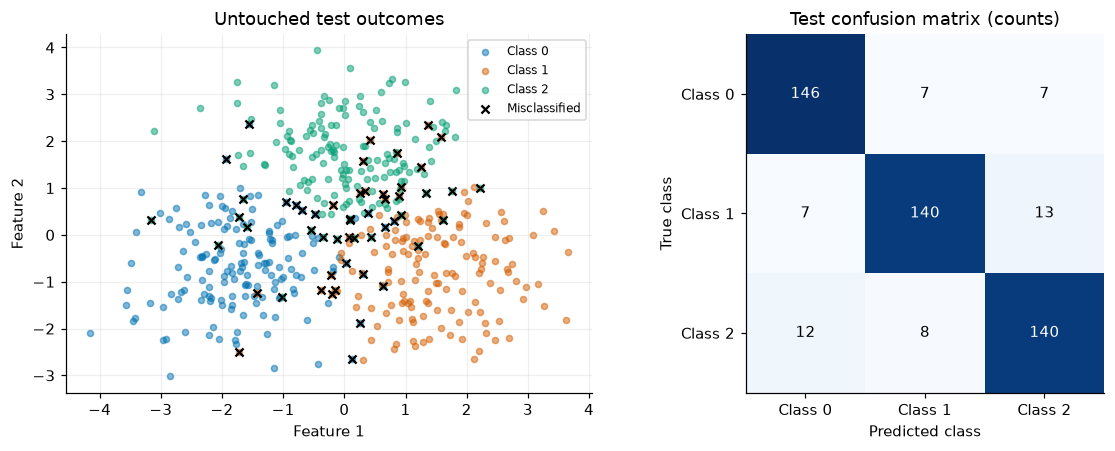

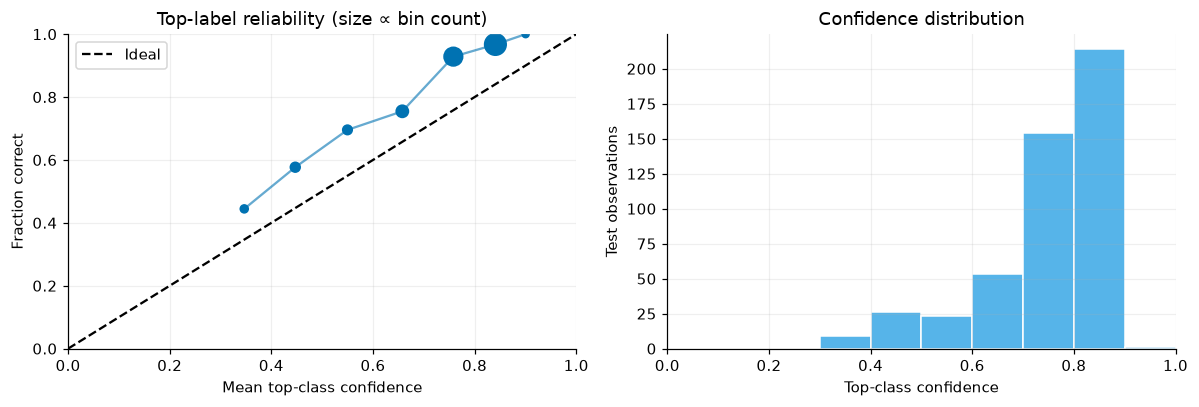

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for k in range(num_classes):
    rows = y[test_idx] == k
    axes[0].scatter(X[test_idx[rows], 0], X[test_idx[rows], 1], s=16, alpha=0.5,
                    color=colors[k], label=class_names[k])
axes[0].scatter(X[test_idx[~correct], 0], X[test_idx[~correct], 1], marker="x",
                s=28, color="black", label="Misclassified")
axes[0].set(title="Untouched test outcomes", xlabel="Feature 1", ylabel="Feature 2")
axes[0].legend(fontsize=8)
cm = test["confusion"]
axes[1].imshow(cm, cmap="Blues")
for i in range(num_classes):
    for j in range(num_classes):
        axes[1].text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[1].set(xticks=range(num_classes), yticks=range(num_classes),
            xticklabels=class_names, yticklabels=class_names,
            xlabel="Predicted class", ylabel="True class", title="Test confusion matrix (counts)")
axes[1].grid(False)
fig.tight_layout(); plt.show()

reliability = test["reliability"].query("count > 0")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot([0, 1], [0, 1], "k--", label="Ideal")
axes[0].plot(reliability.confidence, reliability.accuracy, color="#0072B2", alpha=0.6)
axes[0].scatter(reliability.confidence, reliability.accuracy,
                s=20 + 180 * reliability["count"] / reliability["count"].max(), color="#0072B2")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean top-class confidence",
            ylabel="Fraction correct", title="Top-label reliability (size ∝ bin count)")
axes[0].legend()
axes[1].hist(probabilities.max(axis=1), bins=np.linspace(0, 1, 11), color="#56B4E9", edgecolor="white")
axes[1].set(xlim=(0, 1), xlabel="Top-class confidence", ylabel="Test observations",
            title="Confidence distribution")
fig.tight_layout(); plt.show()


## 5. Does uncertainty identify difficult cases?

Compare the evidence-based score between correct and incorrect predictions, then
sort test cases from lowest to highest uncertainty. The retention curve reports
error among the least-uncertain retained cases. This is a diagnostic ranking, not
a deployed rejection threshold: choosing a threshold requires validation data and
an application-specific cost. Higher uncertainty need not identify every error,
and no out-of-distribution guarantee is implied by this in-distribution example.


In the stored run, many reliability points lie above the diagonal: the classifier is underconfident on this test set. The ECE and reliability counts report this directly. We leave the frozen predictions unchanged rather than using the test set to calibrate them.


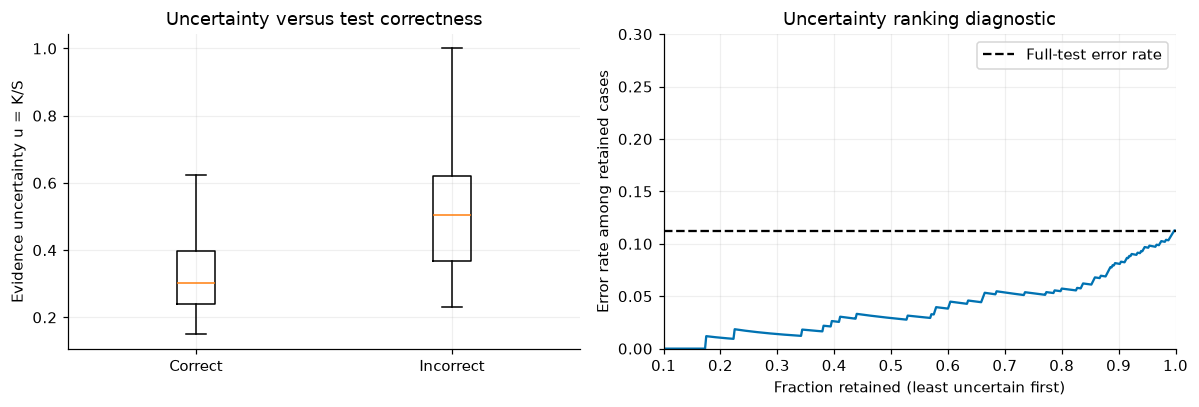

In [6]:
u = evidence_uncertainty.reshape(-1)
rank = np.argsort(u, kind="stable")
retained_count = np.arange(1, len(rank) + 1)
retained_error = np.cumsum(~correct[rank]) / retained_count

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
groups = [u[mask] for mask in [correct, ~correct] if np.any(mask)]
labels = [label for label, mask in [("Correct", correct), ("Incorrect", ~correct)] if np.any(mask)]
axes[0].boxplot(groups, tick_labels=labels, showfliers=False)
axes[0].set(ylabel="Evidence uncertainty u = K/S", title="Uncertainty versus test correctness")
axes[1].plot(retained_count / len(rank), retained_error, color="#0072B2")
axes[1].axhline((~correct).mean(), color="black", linestyle="--", label="Full-test error rate")
axes[1].set(xlim=(0.1, 1), ylim=(0, max(0.3, retained_error[int(0.1 * len(rank)):].max() * 1.1)),
            xlabel="Fraction retained (least uncertain first)", ylabel="Error rate among retained cases",
            title="Uncertainty ranking diagnostic")
axes[1].legend(); fig.tight_layout(); plt.show()


## Apply this to your data

Replace `X` with a finite numeric matrix `(rows, features)` and `y` with integer
class indices `0, ..., K-1`; update class names and model sizes. Define any label
encoding from the intended class vocabulary or training data. Keep the test partition
out of preprocessing, checkpoint selection, calibration, and threshold tuning.
Report class counts and per-class results when classes are imbalanced.

The exact variance identity verifies the distributional calculation, not empirical
calibration or scientific identifiability of the two uncertainty components. For
dropout or model ensembles, use the package's documented hierarchical uncertainty
helpers: averaging only the member variance components omits between-member
disagreement. This tutorial uses one evidential model without dropout.

Scientific references: [Schreck et al., 2024](https://doi.org/10.1175/AIES-D-23-0093.1)
and [Sensoy et al., Evidential Deep Learning](https://arxiv.org/abs/1806.01768).
Original weather workflows are retained under `notebooks/legacy/`.
